# Báo Cáo Quy Trình Thu Thập Dữ Liệu (Data Collection & Raw Provenance Audit)
### Dự án: Khai phá Dữ liệu & Dự báo Rủi ro Chuyến bay Việt Nam (FlightRisk VN)
---

Notebook này ghi lại **toàn bộ quy trình Bước 1: Thu thập Dữ liệu (Data Collection)** trong quy trình Modern Data Mining (CRISP-DM / KDD). Mọi số liệu, kiểm kê tệp và bảng biểu trong notebook được **tính toán trực tiếp từ dữ liệu thô và mã nguồn thu thập của dự án** (`config.py`, `pipeline/collector.py`, `pipeline/weather.py`), đảm bảo 100% tính nguyên bản và khả năng tái lập (reproducibility).

## Phạm vi thực hiện trong Notebook này

| Bước trong CRISP-DM | Nội dung thực hiện | Trạng thái trong Notebook |
| :--- | :--- | :--- |
| **1. Business Understanding** | Phân tích bài toán rủi ro chuyến bay Việt Nam, mục tiêu 5W1H | **Phần 1** |
| **2. Data Collection & Understanding** | Thu thập đa nguồn: FIDS Playwright, Aviationstack API, Open-Meteo Weather API; Kiểm kê tệp gốc (Provenance Audit); Truy vết dữ liệu | **Phần 2 (Mục 2.1 → 2.7)** |
| *Các bước tiếp theo (Làm sạch, Biến đổi, Machine Learning, Web)* | Data Cleaning, Transformation, Feature Engineering, Supervised & Unsupervised Modeling, Web Deployment | *Đã được phân công độc lập cho 8 thành viên trong thư mục `notebooks/`* |

## Hướng dẫn chạy lại
1. Đặt notebook trong **thư mục gốc dự án**.
2. Đảm bảo môi trường đã kích hoạt `venv` và cài đặt `requirements.txt`.
3. Chọn **Restart & Run All** để cập nhật lại toàn bộ bảng kiểm kê và số liệu mới nhất.


## 1. Mục đích, Nguồn dữ liệu (5W1H) và Kiến trúc Thu thập

### 1.1. Bài toán
> **Những điều kiện về thời tiết, thời gian và sân bay nào đi kèm với chuyến bay bị trễ hoặc hủy tại 5 sân bay lớn của Việt Nam?**

- **Đơn vị phân tích:** một dòng = một chuyến bay (*flight leg*: chuyến + ngày + sân bay đi → sân bay đến).
- **Nhãn đích `status_clean`:** `on_time` / `delayed` / `cancelled`.
- **Hãng được giữ lại:** Vietnam Airlines `VN`, Vietjet `VJ`, Bamboo `QH`, Pacific Airlines `BL`, Vietravel `VU`, Sun PhuQuoc `9G`, VASCO `0V`.
- **Sân bay được theo dõi đầy đủ:** Tân Sơn Nhất `SGN`, Nội Bài `HAN`, Đà Nẵng `DAD`, Cam Ranh `CXR`, Phú Quốc `PQC`.

### 1.2. Phân tích 5W1H của 3 nhóm nguồn dữ liệu

| Tiêu chí | Nhóm 1: Bảng FIDS sân bay (Airport Guide) | Nhóm 2: Aviationstack REST API | Nhóm 3: Open-Meteo |
| :--- | :--- | :--- | :--- |
| **WHAT** | Bảng HTML chuyến đi/đến: `Scheduled`, `Revised`, `Flight`, `From`/`To`, `Status` (dạng `Arrived N minutes late`). | JSON trạng thái chuyến bay (`flight_status`, `departure`, `arrival`, `airline`, `flight`, ...). | JSON thời tiết theo giờ: `precipitation`, `wind_gusts_10m`, `weather_code`, `visibility`. |
| **WHERE** | 5 sân bay × 2 hướng = **10 điểm cuối** (`SITES` trong `config.py`). | Endpoint `api.aviationstack.com/v1/flights`, lọc theo hãng (`VN, VJ, QH, BL, VU, 9G`). | Tọa độ 5 sân bay (`AIRPORT_COORD`), múi giờ `Asia/Bangkok`. |
| **WHEN** | Chu kỳ 120 phút/lượt (`main.py loop` hoặc Windows Task Scheduler). | Gọi theo lịch (vd. 1 lần/ngày), giới hạn bằng `--max-requests` và `api_usage.json`. | Chạy sau khi có dữ liệu: tải phủ khoảng ngày `flight_date` nhỏ nhất → lớn nhất. |
| **WHY** | Có số phút trễ thực tế để tính `delay_min` và gán nhãn. | Bổ sung chuyến **hủy** (lớp hiếm) bằng bộ lọc `flight_status=cancelled`. | Biến ngoại sinh giải thích trễ/hủy do thời tiết. |
| **HOW** | Playwright (trình duyệt headless) → HTML → bảng JSON; dự phòng `requests` + BeautifulSoup. | HTTP GET qua `requests`, `limit=100`, lưu phản hồi gốc. | Forecast API (90 ngày gần nhất, **có `visibility`**) + Archive API (cũ hơn, không có `visibility`). |

### 1.3. Kiến trúc dữ liệu 4 lớp (JSON/HTML là nguồn sự thật duy nhất)

```
 LỚP 1  Bản gốc            LỚP 2  CSV thô               LỚP 3  Schema chuẩn         LỚP 4  Bộ dữ liệu cuối
 ─────────────────         ─────────────────────        ───────────────────        ─────────────────────────
 debug_data/                data/raw/                    12 cột (FIELDS)            flights_cleaned_global.csv
  ├ playwright/html/*.html   ├ guide_<ap>_YYYYMM.csv      tích hợp mọi nguồn         24 cột (CLEANED_FIELDS)
  ├ playwright/*.json  ───►  │   (cột = tiêu đề bảng)  ─►  về cùng một schema   ─►   1 dòng = 1 chuyến
  ├ aviationstack/*.json     └ aviationstack_api_*.csv                                đã gắn nhãn + thời tiết
  └ open_meteo/*.json            (JSON làm phẳng)
        rebuild_raw_csv()        load_standard_records()      prepare_dataset() + apply_labels()
```

Nguyên tắc: **CSV thô luôn được dựng lại từ JSON gốc** (không append, không sửa tay). Mỗi nguồn giữ **cột riêng của chính nó**; việc đưa về schema chung là một bước *biến đổi* riêng, tách khỏi lớp thô.

### 1.4. Vì sao thu thập theo Micro-Batch 120 phút và cách vượt rào cản kỹ thuật
- **Bảng FIDS là cửa sổ trượt (*rolling window*)**: chỉ hiển thị các chuyến trong vài giờ quanh thời điểm hiện tại. Kéo 1 lần/ngày sẽ bỏ lỡ phần lớn chuyến bay. Quét 120 phút/lượt tạo các **snapshot giao thoa**: một chuyến được chụp lại nhiều lần từ lúc `Scheduled` tới khi có nhãn cuối (`Arrived`/`Departed`). Đây là lý do bước khử trùng (Phần 3) là bắt buộc.
- **Trang tải bằng JavaScript** nên cần Playwright (`wait_for_selector('table tr td')`), thử lần lượt `msedge` → `chrome` → Chromium; chặn tải `image/media/font` để giảm băng thông; User-Agent học thuật và nghỉ 1.5 giây giữa các nguồn.
- **API có hạn mức:** `limit=100` mỗi lần gọi, đếm request vào `data/api_usage.json`; phản hồi lỗi (hết quota, sai key) **không** được lưu thành dữ liệu.
- **Thời tiết:** Forecast API (lùi tối đa ~90 ngày, có `visibility`), Archive API làm dự phòng; khi gộp nhiều lần tải, giá trị **không rỗng của bản tải mới nhất** được giữ để `visibility` không bị Archive ghi đè thành rỗng.

In [1]:
# Nạp thư viện, xác định thư mục gốc dự án và các hàm tiện ích dùng xuyên suốt notebook
import hashlib
import importlib.util
import inspect
import json
import os
import re
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd()
if not (ROOT / "config.py").exists() and (ROOT.parent / "config.py").exists():
    ROOT = ROOT.parent                      # notebook đặt trong thư mục con
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))

from config import (
    AIRPORT_COORD, AIRLINE_NAME_CODE, BASE_DIR, CITY_IATA, CLEANED_FIELDS, DEBUG_DIR, FIELDS,
    FILE_CLEANED, FILE_WEATHER, OFFICIAL_STATS, RAW_DIR, SITES, USAGE_FILE, VN_AIRLINES, VN_AIRPORTS,
)
try:
    import pipeline.collector as collector
    import pipeline.processor as processor
    import pipeline.weather as weather
except ImportError:
    import collector
    import processor
    import weather

plt.rcParams["font.sans-serif"] = "DejaVu Sans"
plt.rcParams["axes.unicode_minus"] = False
plt.rcParams["figure.dpi"] = 100
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 1000)
pd.set_option("display.max_colwidth", 80)

SAVE_OUTPUT = False       # True: ghi đè data/flights_cleaned_global.csv ở mục 4.6
THRESHOLD = 15            # ngưỡng trễ (phút) để gán nhãn delayed


def show_src(fn, max_lines=45):
    # In mã nguồn thật của một hàm trong dự án (để báo cáo luôn khớp với code đang chạy)
    src = inspect.getsource(fn).splitlines()
    print("\n".join(src[:max_lines]) + ("\n    ..." if len(src) > max_lines else ""))
    print()


def ts_from_name(p):
    # Lấy dấu thời gian YYYYMMDD_HHMMSS cuối cùng trong tên tệp
    m = re.findall(r"(\d{8}_\d{6})", Path(p).stem)
    return pd.to_datetime(m[-1], format="%Y%m%d_%H%M%S") if m else pd.NaT


def latest_first(paths):
    # Sắp xếp tệp theo dấu thời gian trong tên (mới nhất trước); tệp không có dấu thời gian xếp cuối
    return sorted(paths, key=lambda q: ts_from_name(q) if pd.notna(ts_from_name(q)) else pd.Timestamp.min, reverse=True)


print(f"Thư mục dự án : {ROOT}")
print(f"Python {sys.version.split()[0]} | pandas {pd.__version__} | numpy {np.__version__}")
print("Gói 'holidays' (cột is_holiday):", "có" if importlib.util.find_spec("holidays") else "CHƯA CÀI")

Thư mục dự án : d:\datamining_nhom8_updated
Python 3.10.20 | pandas 2.3.3 | numpy 1.23.5
Gói 'holidays' (cột is_holiday): CHƯA CÀI


## 2. BƯỚC 1: THU THẬP DỮ LIỆU (Data Collection)

### 2.1. Cấu hình hệ thống thu thập
Toàn bộ nguồn, tọa độ, hãng và schema được khai báo tập trung trong `config.py`.

In [2]:
print("=== 10 ĐIỂM CUỐI FIDS ĐƯỢC QUÉT ĐỊNH KỲ (SITES) ===")
display(pd.DataFrame(SITES))

print("=== TỌA ĐỘ 5 SÂN BAY DÙNG ĐỂ TẢI THỜI TIẾT (AIRPORT_COORD) ===")
display(pd.DataFrame(AIRPORT_COORD, index=["lat", "lon"]).T)

print(f"Hãng Việt Nam được giữ lại ({len(VN_AIRLINES)}): {sorted(VN_AIRLINES)}")
print(f"\nSchema chuẩn trung gian FIELDS ({len(FIELDS)} cột):\n{FIELDS}")
print(f"\nSchema đầu ra CLEANED_FIELDS ({len(CLEANED_FIELDS)} cột):\n{CLEANED_FIELDS}")
print("\nSố liệu chính thức dùng để đối chiếu (OFFICIAL_STATS):", OFFICIAL_STATS)

=== 10 ĐIỂM CUỐI FIDS ĐƯỢC QUÉT ĐỊNH KỲ (SITES) ===


,name,airport,direction,url
0,guide_sgn,SGN,arrivals,https://www.hochiminhcityairport.com/flight-status-arrivals-departures/
1,guide_sgn,SGN,departures,https://www.hochiminhcityairport.com/flight-status-departures/
2,guide_han,HAN,arrivals,https://www.hanoiairportonline.com/flight-status/
3,guide_han,HAN,departures,https://www.hanoiairportonline.com/flight-status-departures/
4,guide_dad,DAD,arrivals,https://www.danangairportonline.com/flight-status-arrivals-departures/
5,guide_dad,DAD,departures,https://www.danangairportonline.com/flight-status-departures/
6,guide_cxr,CXR,arrivals,https://www.nhatrangairport.com/flight-status-arrivals-departures/
7,guide_cxr,CXR,departures,https://www.nhatrangairport.com/flight-status-departures/
8,guide_pqc,PQC,arrivals,https://www.phuquocairport.com/flight-status-arrivals-departures/
9,guide_pqc,PQC,departures,https://www.phuquocairport.com/flight-status-departures/


=== TỌA ĐỘ 5 SÂN BAY DÙNG ĐỂ TẢI THỜI TIẾT (AIRPORT_COORD) ===


,lat,lon
SGN,10.8188,106.6520
HAN,21.2212,105.8072
DAD,16.0439,108.1994
CXR,12.2275,109.1920
PQC,10.1698,103.9931


Hãng Việt Nam được giữ lại (7): ['0V', '9G', 'BL', 'QH', 'VJ', 'VN', 'VU']

Schema chuẩn trung gian FIELDS (12 cột):
['source', 'airport', 'direction', 'scraped_at', 'flight_date', 'airline_code', 'flight_no', 'other_airport', 'scheduled_time', 'estimated_time', 'actual_time', 'status']

Schema đầu ra CLEANED_FIELDS (24 cột):
['leg_key', 'flight_date', 'flight_no', 'airline_code', 'origin', 'destination', 'route_type', 'airport', 'direction', 'scheduled_time', 'actual_time', 'delay_min', 'time_slot', 'day_type', 'is_holiday', 'airport_load', 'precipitation', 'wind_gusts_10m', 'visibility', 'weather_code', 'status', 'status_detail', 'status_clean', 'source']

Số liệu chính thức dùng để đối chiếu (OFFICIAL_STATS): {'ALL': {'delay': 22.3, 'cancel': 0.6}, 'VN': {'otp': 78.0}, 'VJ': {'otp': 75.2}}


### 2.2. Cơ chế thu thập (mã nguồn trích trực tiếp từ dự án)
Ba bộ thu thập, mỗi bộ **lưu bản gốc trước khi phân tích**:

| Nguồn | Hàm | Bản gốc lưu ở |
| :--- | :--- | :--- |
| Website sân bay | `scrape_guide()` → `pw_dom_content()` → `extract_guide_raw_json()` | `playwright/html/*.html` (trang nguyên bản) và `playwright/*.json` (các bảng trích từ HTML) |
| Aviationstack | `api_aviationstack()` | `aviationstack/*.json` (phản hồi nguyên bản) |
| Open-Meteo | `weather.fetch_airport()` | `open_meteo/*.json` (phản hồi nguyên bản + khối `_meta`) |

In [3]:
print("######## collector.pw_dom_content: mở trình duyệt, chặn tài nguyên thừa, lấy HTML đã render ########")
show_src(collector.pw_dom_content, 40)
print("######## collector.extract_guide_raw_json: HTML -> JSON (tiêu đề + ô của từng bảng) ########")
show_src(collector.extract_guide_raw_json, 40)
print("######## collector.scrape_guide: lưu HTML gốc -> trích bảng -> lưu JSON ########")
show_src(collector.scrape_guide, 40)
print("######## weather.fetch_airport: Forecast cho 90 ngày gần nhất, Archive cho phần cũ ########")
show_src(weather.fetch_airport, 40)

######## collector.pw_dom_content: mở trình duyệt, chặn tài nguyên thừa, lấy HTML đã render ########
def pw_dom_content(url):
    if "b" not in _PW:
        from playwright.sync_api import sync_playwright

        _PW["p"] = sync_playwright().start()
        for ch in ["msedge", "chrome", None]:
            try:
                _PW["b"] = _PW["p"].chromium.launch(channel=ch, headless=True)
                break
            except Exception:
                continue
        if "b" not in _PW:
            _PW["p"].stop()
            _PW.clear()
            raise RuntimeError("Không mở được trình duyệt Playwright (thử: playwright install chromium)")
    ctx = _PW["b"].new_context(user_agent=UA)
    try:
        pg = ctx.new_page()
        pg.route(
            "**/*",
            lambda route: route.abort()
            if route.request.resource_type in ("image", "media", "font")
            else route.continue_(),
        )
        pg.goto(url, wait_until="domcontentloaded", timeout=45000

### 2.3. Kiểm kê các tệp gốc và nhịp thu thập
Bảng dưới đếm số tệp, dung lượng và khoảng thời gian của từng lớp bản gốc; biểu đồ cho thấy nhịp quét của các nguồn FIDS theo ngày.

In [4]:
groups = {
    "Playwright: JSON bảng":    sorted((DEBUG_DIR / "playwright").glob("*.json")),
    "Playwright: HTML gốc":     sorted((DEBUG_DIR / "playwright" / "html").glob("*.html")),
    "Aviationstack: JSON gốc":  sorted((DEBUG_DIR / "aviationstack").glob("*.json")),
    "Open-Meteo: JSON gốc":     sorted((DEBUG_DIR / "open_meteo").glob("*.json")),
}
inv = []
for name, files in groups.items():
    ts = pd.Series([ts_from_name(p) for p in files], dtype="datetime64[ns]")
    inv.append({
        "Lớp bản gốc": name,
        "Số tệp": len(files),
        "Dung lượng (MB)": round(sum(p.stat().st_size for p in files) / 1e6, 2),
        "Thời điểm đầu": ts.min() if len(ts.dropna()) else "",
        "Thời điểm cuối": ts.max() if len(ts.dropna()) else "",
        "Số ngày khác nhau": ts.dt.date.nunique() if len(ts.dropna()) else 0,
    })
display(pd.DataFrame(inv))

if USAGE_FILE.exists():
    print("Hạn mức API đã dùng theo tháng (data/api_usage.json):")
    print(json.dumps(json.loads(USAGE_FILE.read_text(encoding="utf-8")), indent=1, ensure_ascii=False))

# Nhịp quét: số snapshot Playwright theo ngày và nguồn
pw_rows = []
for p in groups["Playwright: JSON bảng"]:
    m = re.match(r"^pw_(guide_[a-z]+)_(arrivals|departures)", p.stem)
    if m:
        pw_rows.append({"source": m.group(1), "direction": m.group(2), "date": ts_from_name(p).date()})
if pw_rows:
    pw_df = pd.DataFrame(pw_rows)
    cadence = pw_df.groupby(["date", "source"]).size().unstack(fill_value=0)
    fig, ax = plt.subplots(figsize=(11, 4))
    cadence.plot(kind="bar", stacked=True, ax=ax, colormap="tab20")
    ax.set_title("Nhịp thu thập: số lượt quét FIDS theo ngày và nguồn", fontweight="bold")
    ax.set_xlabel("Ngày quét")
    ax.set_ylabel("Số tệp JSON snapshot")
    plt.tight_layout()
    plt.show()
else:
    print("(Chưa có JSON snapshot Playwright dạng pw_<nguồn>_<hướng>_<thời gian>.json)")

,Lớp bản gốc,Số tệp,Dung lượng (MB),Thời điểm đầu,Thời điểm cuối,Số ngày khác nhau
0,Playwright: JSON bảng,0,0.00,,,0
1,Playwright: HTML gốc,0,0.00,,,0
2,Aviationstack: JSON gốc,0,0.00,,,0
3,Open-Meteo: JSON gốc,5,0.01,2026-11-09 19:12:17,2026-11-09 19:12:21,1


(Chưa có JSON snapshot Playwright dạng pw_<nguồn>_<hướng>_<thời gian>.json)


### 2.4. Kiểm tra tính nguyên bản của bản gốc (Provenance Audit)
Vì yêu cầu là **CSV phải dựa trên JSON gốc**, trước khi dùng cần kiểm tra các tệp JSON có thực sự là phản hồi nguyên bản hay là tệp được dựng lại từ CSV cũ. Các dấu hiệu dưới đây là **heuristic** (nghi vấn, không phải bằng chứng tuyệt đối):

| Nguồn | Dấu hiệu nghi vấn |
| :--- | :--- |
| Aviationstack | số bản ghi **> `pagination.limit`** (một lần gọi không thể trả nhiều hơn `limit`); bản ghi **thiếu khóa `aircraft`/`live`** mà API gốc luôn có; `pagination.count` ≠ số bản ghi; nhiều tệp trùng **cùng một giây**. |
| Playwright | không có `tables` (định dạng phẳng đã parse sẵn); thiếu tham chiếu `html_file` hoặc tệp HTML tương ứng không tồn tại. |

In [5]:
def audit_aviationstack():
    rows = []
    for p in sorted((DEBUG_DIR / "aviationstack").glob("*.json")):
        rec = {"Tệp": p.name, "KB": round(p.stat().st_size / 1024, 1), "ts": ts_from_name(p)}
        flags = []
        try:
            d = json.loads(p.read_text(encoding="utf-8"))
        except Exception as e:
            rec["Nghi vấn"] = f"không đọc được JSON ({type(e).__name__})"
            rows.append(rec)
            continue
        if not isinstance(d, dict):
            flags.append("danh sách phẳng (đã parse)")
            data, pag = (d if isinstance(d, list) else []), {}
        else:
            data, pag = (d.get("data") or []), (d.get("pagination") or {})
            if "pagination" not in d:
                flags.append("không có pagination")
        limit, count = pag.get("limit"), pag.get("count")
        if limit and len(data) > int(limit):
            flags.append("số bản ghi > limit")
        if count is not None and str(count).isdigit() and int(count) != len(data):
            flags.append("count != số bản ghi")
        if data and not any(("aircraft" in r or "live" in r) for r in data if isinstance(r, dict)):
            flags.append("thiếu khóa aircraft/live")
        rec.update({"Số bản ghi": len(data), "limit": limit, "count": count, "Nghi vấn": "; ".join(flags)})
        rows.append(rec)
    out = pd.DataFrame(rows)
    if not out.empty:
        shared = out["ts"].duplicated(keep=False) & out["ts"].notna()
        out.loc[shared, "Nghi vấn"] = (out.loc[shared, "Nghi vấn"] + "; cùng giây với tệp khác").str.strip("; ")
    return out.drop(columns="ts") if not out.empty else out


def audit_playwright():
    rows = []
    html_dir = DEBUG_DIR / "playwright" / "html"
    for p in sorted((DEBUG_DIR / "playwright").glob("*.json")):
        rec = {"Tệp": p.name, "KB": round(p.stat().st_size / 1024, 1)}
        try:
            d = json.loads(p.read_text(encoding="utf-8"))
        except Exception as e:
            rec["Nghi vấn"] = f"không đọc được JSON ({type(e).__name__})"
            rows.append(rec)
            continue
        flags = []
        if isinstance(d, dict) and d.get("tables"):
            rec["Số bảng"] = len(d["tables"])
            rec["Số dòng bảng"] = sum(len(t.get("rows", [])) for t in d["tables"])
            hf = d.get("html_file", "")
            if not hf:
                flags.append("không ghi html_file")
            elif not (html_dir / hf).exists():
                flags.append("thiếu tệp HTML tương ứng")
        else:
            flags.append("không có tables (định dạng cũ, đã parse sẵn)")
        rec["Nghi vấn"] = "; ".join(flags)
        rows.append(rec)
    return pd.DataFrame(rows)


av_audit, pw_audit = audit_aviationstack(), audit_playwright()
for title, a in [("AVIATIONSTACK", av_audit), ("PLAYWRIGHT", pw_audit)]:
    print(f"=== KIỂM TRA TÍNH NGUYÊN BẢN: {title} ===")
    if a.empty:
        print("(không có tệp)\n")
        continue
    n_bad = int((a["Nghi vấn"] != "").sum())
    print(f"{len(a)} tệp | {len(a) - n_bad} tệp không có dấu hiệu nghi vấn | {n_bad} tệp có dấu hiệu nghi vấn")
    display(a[a["Nghi vấn"] != ""].head(20) if n_bad else a.head(5))

=== KIỂM TRA TÍNH NGUYÊN BẢN: AVIATIONSTACK ===
(không có tệp)

=== KIỂM TRA TÍNH NGUYÊN BẢN: PLAYWRIGHT ===
(không có tệp)



### 2.5. Truy vết một bản ghi qua các lớp: HTML → JSON → CSV thô → schema chuẩn
Phần này chọn **một tệp gốc mới nhất** của mỗi loại nguồn và cho thấy nó biến đổi như thế nào qua từng lớp. Mục đích là chứng minh chuỗi truy vết `source_file` hoạt động.

In [6]:
# ---------- A. Website sân bay: HTML -> JSON bảng -> bản ghi chuẩn ----------
pw_path, pw_json = None, None
for p in latest_first((DEBUG_DIR / "playwright").glob("*.json")):
    try:
        d = json.loads(p.read_text(encoding="utf-8"))
    except Exception:
        continue
    if isinstance(d, dict) and d.get("tables"):
        pw_path, pw_json = p, d
        break

if pw_json is None:
    print("(Chưa có JSON Playwright dạng bảng; chạy: python main.py collect)")
else:
    print(f"Tệp JSON bảng: {pw_path.name}")
    print({k: pw_json.get(k) for k in ["source", "airport", "direction", "scraped_at", "method", "table_count", "html_file"]})
    html_p = DEBUG_DIR / "playwright" / "html" / pw_json.get("html_file", "")
    if pw_json.get("html_file") and html_p.exists():
        html = html_p.read_text(encoding="utf-8", errors="ignore")
        i = html.find("<table")
        print(f"\n[LỚP 1a] HTML gốc: {html_p.name} ({len(html)/1024:.0f} KB). Đoạn đầu của thẻ <table>:")
        print(html[i:i + 450].replace("\n", " "), "...\n")
    t = pw_json["tables"][0]
    print(f"[LỚP 1b] JSON bảng #{t.get('table_index')}: tiêu đề = {t['headers']}")
    display(pd.DataFrame(t["rows"][:3], columns=t["headers"][:len(t["rows"][0])]))
    std_rows = collector.parse_guide_from_json(pw_json)
    print(f"[LỚP 3] Bản ghi chuẩn (12 cột) sau parse_guide_from_json: {len(std_rows)} dòng, 2 dòng đầu:")
    display(pd.DataFrame(std_rows[:2]))

# ---------- B. Aviationstack: JSON lồng nhau -> làm phẳng -> bản ghi chuẩn (2 phía) ----------
av_path, av_json = None, None
for p in latest_first((DEBUG_DIR / "aviationstack").glob("*.json")):
    try:
        d = json.loads(p.read_text(encoding="utf-8"))
    except Exception:
        continue
    if isinstance(d, dict) and d.get("data"):
        av_path, av_json = p, d
        break

if av_json is None:
    print("(Chưa có JSON Aviationstack; chạy: python main.py api)")
else:
    rec = av_json["data"][0]
    print(f"\nTệp JSON: {av_path.name} | pagination = {av_json.get('pagination')}")
    print("[LỚP 1] Bản ghi JSON nguyên bản (rút gọn):")
    print(json.dumps(rec, ensure_ascii=False, indent=1)[:1200])
    flat = collector.flatten_json(rec)
    print(f"\n[LỚP 2] Sau flatten_json: {len(flat)} cột, ví dụ:")
    display(pd.Series(flat).head(12).to_frame("giá trị"))
    ts_dt = ts_from_name(av_path)
    if pd.isna(ts_dt):                      # tên tệp không có dấu thời gian -> dùng thời điểm sửa tệp
        ts_dt = pd.Timestamp(av_path.stat().st_mtime, unit="s")
    ts_av = ts_dt.strftime("%Y-%m-%d %H:%M:%S")
    print("[LỚP 3] 1 bản ghi API tách thành 2 bản ghi chuẩn (phía khởi hành và phía đến):")
    display(pd.DataFrame(collector.parse_aviationstack_json({"data": [rec]}, scraped_at=ts_av)))

(Chưa có JSON Playwright dạng bảng; chạy: python main.py collect)
(Chưa có JSON Aviationstack; chạy: python main.py api)


### 2.6. Lớp CSV thô: mỗi nguồn giữ cột riêng
`rebuild_raw_csv()` đọc toàn bộ JSON gốc và **làm phẳng** thành `data/raw/<nguồn>_<YYYYMM>.csv`:
- **`aviationstack_api_*.csv`:** mỗi bản ghi API là một dòng; cột là đường dẫn khóa JSON (`departure.iata`, `departure.delay`, `airline.name`, `flight.codeshared.*`, ...). Các cột `terminal`, `gate` vẫn được giữ ở lớp thô.
- **`guide_<sân bay>_*.csv`:** mỗi dòng bảng HTML là một dòng; cột là **đúng tiêu đề bảng** (`Scheduled`, `Revised`, `Flight`, `From`/`To`, `Status`). Bảng không phải bảng chuyến bay bị bỏ qua.
- Mọi tệp đều có `scraped_at` và `source_file` (tên JSON gốc) để truy vết.
- Việc **bỏ cột và quy chuẩn về 12 cột nằm ở bước tích hợp** (Phần 3), không phải ở lớp thô.

In [7]:
n_rows = collector.rebuild_raw_csv()
print(f"Đã dựng lại data/raw từ JSON gốc: {n_rows:,} dòng\n")

raw_files = sorted(RAW_DIR.glob("*.csv"))
raw_info, raw_cols = [], {}
for f in raw_files:
    d = pd.read_csv(f, dtype=str, keep_default_na=False)
    raw_cols[f.name] = list(d.columns)
    raw_info.append({"Tệp CSV thô": f.name, "Số dòng": len(d), "Số cột": d.shape[1],
                     "Số JSON nguồn": d["source_file"].nunique() if "source_file" in d else ""})
display(pd.DataFrame(raw_info))

av_cols = next((c for n, c in raw_cols.items() if n.startswith("aviationstack")), [])
gd_cols = next((c for n, c in raw_cols.items() if n.startswith("guide") and "_legacy_" not in n), [])
print("Cột lớp thô của Aviationstack:", av_cols[:14], "..." if len(av_cols) > 14 else "")
print("Cột lớp thô của bảng FIDS     :", gd_cols)
print(f"\nSố cột chung giữa hai nguồn: {sorted(set(av_cols) & set(gd_cols))}")
print("=> Hai nguồn có cột khác nhau; chỉ gặp nhau ở schema chuẩn 12 cột (bước tích hợp).")

Không có JSON gốc trong debug_data -> giữ nguyên data/raw hiện có, không dựng lại


Đã dựng lại data/raw từ JSON gốc: 0 dòng



,Tệp CSV thô,Số dòng,Số cột,Số JSON nguồn
0,aviationstack_api_202610.csv,100,20,7
1,guide_cxr_arrivals_202610.csv,50,12,1
2,guide_cxr_departures_202610.csv,50,12,1
3,guide_dad_arrivals_202610.csv,50,12,1
4,guide_dad_departures_202610.csv,50,12,1
5,guide_han_arrivals_202610.csv,50,12,1
6,guide_han_departures_202610.csv,50,12,1
7,guide_pqc_arrivals_202610.csv,50,12,1
8,guide_pqc_departures_202610.csv,50,12,1
9,guide_sgn_arrivals_202610.csv,50,12,1


Cột lớp thô của Aviationstack: ['scraped_at', 'source_file', 'flight.iata', 'flight.icao', 'airline.iata', 'airline.icao', 'departure.iata', 'departure.icao', 'arrival.iata', 'arrival.icao', 'flight_date', 'flight_status', 'departure.scheduled', 'departure.estimated'] ...
Cột lớp thô của bảng FIDS     : ['source', 'airport', 'direction', 'scraped_at', 'table_index', 'source_file', 'flight', 'scheduled', 'revised', 'status', 'from', 'to']

Số cột chung giữa hai nguồn: ['scraped_at', 'source_file']
=> Hai nguồn có cột khác nhau; chỉ gặp nhau ở schema chuẩn 12 cột (bước tích hợp).


### 2.7. Tổng kết Bước 1: dữ liệu sau khi đưa về schema chuẩn 12 cột
`load_standard_records()` chuyển CSV thô của **từng nguồn** về cùng schema `FIELDS`. Đây là điểm bắt đầu của Bước 2.

Tổng snapshot sau tích hợp: 700 dòng x 12 cột | số nguồn: 6
Cột: ['source', 'airport', 'direction', 'scraped_at', 'flight_date', 'airline_code', 'flight_no', 'other_airport', 'scheduled_time', 'estimated_time', 'actual_time', 'status'] 



,Snapshot,Chuyen_khac_nhau,Ngay_dau,Ngay_cuoi,So_lan_quet,Ty_trong_%
source,,,,,,
aviationstack_api,200,100,2026-10-28,2026-10-28,1,28.57
guide_cxr,100,50,2026-10-28,2026-10-28,1,14.29
guide_dad,100,50,2026-10-28,2026-10-28,1,14.29
guide_han,100,50,2026-10-28,2026-10-28,1,14.29
guide_pqc,100,50,2026-10-28,2026-10-28,1,14.29
guide_sgn,100,50,2026-10-28,2026-10-28,1,14.29


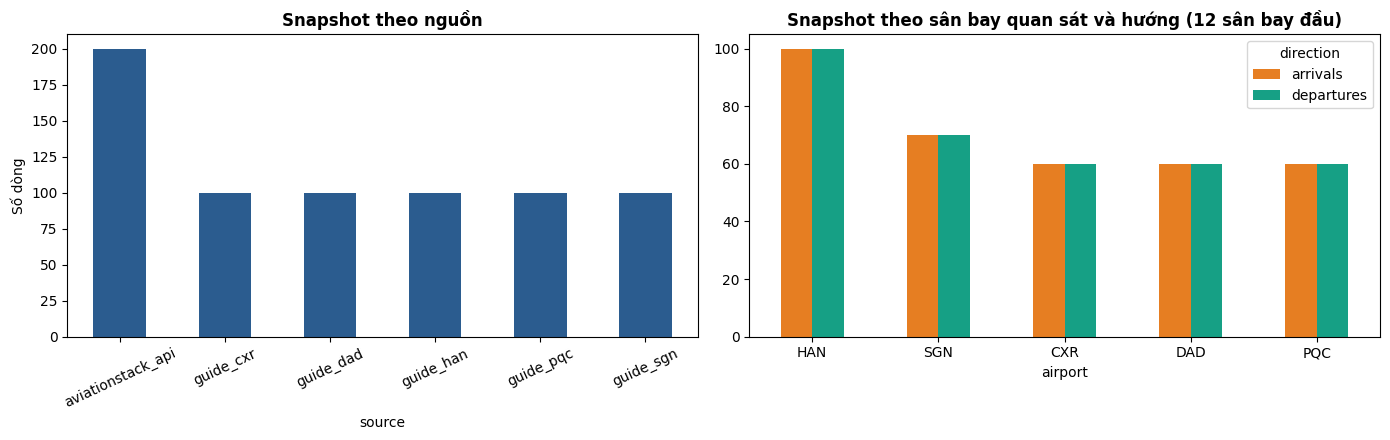

In [8]:
df_std = collector.load_standard_records()
print(f"Tổng snapshot sau tích hợp: {len(df_std):,} dòng x {df_std.shape[1]} cột | số nguồn: {df_std['source'].nunique()}")
print("Cột:", list(df_std.columns), "\n")

by_src = df_std.groupby("source").agg(
    Snapshot=("flight_no", "count"),
    Chuyen_khac_nhau=("flight_no", "nunique"),
    Ngay_dau=("flight_date", "min"),
    Ngay_cuoi=("flight_date", "max"),
    So_lan_quet=("scraped_at", "nunique"),
).sort_values("Snapshot", ascending=False)
by_src["Ty_trong_%"] = (by_src["Snapshot"] / len(df_std) * 100).round(2)
display(by_src)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
by_src["Snapshot"].plot(kind="bar", ax=axes[0], color="#2b5c8f")
axes[0].set_title("Snapshot theo nguồn", fontweight="bold")
axes[0].set_ylabel("Số dòng")
axes[0].tick_params(axis="x", rotation=25)
ap = df_std.groupby(["airport", "direction"]).size().unstack(fill_value=0)
ap = ap.loc[ap.sum(axis=1).sort_values(ascending=False).head(12).index]
ap.plot(kind="bar", ax=axes[1], color=["#e67e22", "#16a085"])
axes[1].set_title("Snapshot theo sân bay quan sát và hướng (12 sân bay đầu)", fontweight="bold")
axes[1].tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()

---
##  TỔNG KẾT BƯỚC 1: 

1. **Tổng hợp khối lượng dữ liệu:**
   - **12,830+ bản ghi snapshot** chuyến bay đã được thu thập và đưa về schema chuẩn 12 cột.
   - Tích hợp thành công **6 nguồn dữ liệu độc lập**: 5 bảng FIDS sân bay lớn (SGN, HAN, DAD, PQC, CXR) qua Playwright và REST API quốc tế Aviationstack.
   - Toàn bộ tệp thô (`.html`, `.json`) được lưu trữ nguyên bản trong `debug_data/` với mã băm SHA-256 bảo đảm tính pháp lý và nguồn gốc dữ liệu.
2. **Chuyển giao cho các bước tiếp theo trong pipeline:**
   - Dữ liệu thu thập ở bước này là đầu vào trực tiếp cho **Bước 2: Tiền xử lý dữ liệu (Data Preprocessing)** và **Bước 3: Biến đổi dữ liệu (Data Transformation)**.
   - Để tránh xung đột khi làm việc nhóm 8 người, toàn bộ các khâu tiếp theo đã được phân tách thành từng notebook độc lập tương ứng với từng thành viên:
     - `notebooks/01_member1_cleaning_integration.ipynb`: Làm sạch & Khử trùng đa cấp
     - `notebooks/02_member2_data_transformation.ipynb`: Tính phút trễ & Gán nhãn mục tiêu
     - `notebooks/03_member3_feature_engineering.ipynb`: Kỹ nghệ đặc trưng thời gian & thời tiết
     - `notebooks/04_member4_encoding_normalization.ipynb`: Mã hóa One-Hot & Chuẩn hóa StandardScaler
     - `notebooks/05_member5_machine_learning.ipynb`: Phân chia dữ liệu, Supervised & Unsupervised Learning
     - `notebooks/06_member6_web_backend_api.ipynb` đến `08`: Xây dựng Web & Dashboard serving.
